# Saving and loading models

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These tutorials use a CPU and the full original SIRDS bank. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `7a0813987944`](https://github.com/OJWatson/metis/tree/7a081398794492c82d92812b5801900f62f8639a).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Short uv setup cell shared by downloadable notebooks."""

import os
from pathlib import Path
import re
import shlex
import subprocess
import sys


def prepare_colab(revision):
    """Use the checkout's locked environment in Colab's active interpreter."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    if not (os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION")):
        print("Using your local METIS environment.")
        return
    # The source commit matches the results saved in this notebook.
    source = Path("/content/metis-tutorial")
    commands = f'''
set -euo pipefail
export PATH="$HOME/.local/bin:$PATH"
command -v uv >/dev/null || curl -LsSf https://astral.sh/uv/0.7.22/install.sh | sh
[ -d {source}/.git ] || git clone -q https://github.com/OJWatson/metis.git {source}
git -C {source} fetch -q origin {revision}
git -C {source} checkout -q --detach {revision}
uv sync --project {source} --python {shlex.quote(sys.executable)} --locked --inexact --no-dev --extra docs --no-editable
'''
    subprocess.run(
        ["bash", "-c", commands], check=True,
        env={**os.environ, "UV_PROJECT_ENVIRONMENT": sys.prefix, "UV_NO_MODIFY_PATH": "1"},
    )
    print("METIS is ready. If Colab reports a library-version conflict or asks for a restart, restart the session, then Run all.")


prepare_colab("7a081398794492c82d92812b5801900f62f8639a")


Once trained, we'd like to use our surrogate in downstream applications: a
model fitting routine, a script exploring scenarios, or an interactive
dashboard. We may also want to resume training after an interruption. METIS
provides a saved surrogate for predictions and a training checkpoint for
continuing a fit.

## Saving a fitted surrogate

This page uses the MLP from the [training walkthrough](https://ojwatson.github.io/metis/basics/training.html), fitted
on the full original SIRDS bank with 1,000 parameter settings, five realisations
each and 200 daily outputs. To make the notebook runnable on its own, the setup
below repeats that short fit if a matching saved model is not already present.

In [1]:
#| code-fold: true
#| code-summary: "Load the SIRDS example and prepare the MLP if needed"
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from metis import Surrogate, TrainingConfig, load_example

bank = load_example()
split = bank.split(seed=42)
model = Surrogate.load("sirds_surrogate.pt") if Path("sirds_surrogate.pt").exists() else None
if (model is None or model.model_name != "mlp"
        or model.training_metadata.get("training_fingerprint") != split.train.fingerprint):
    model = Surrogate("mlp").fit(
        split.train, split.validation,
        config=TrainingConfig(steps=1000, batch_size=64, eval_every=100, seed=42),
    )

Save the fitted model with:

In [2]:
model.save("sirds_surrogate.pt")

PosixPath('sirds_surrogate.pt')

The file includes the model architecture, weights, input and output names,
time grid and fitted scalers. You can copy it to another computer with METIS
installed; the original simulations are not needed for prediction.

## Loading and making predictions

Load the model and supply named simulator inputs. Here we use one held-out
SIRDS setting so we can compare its prediction with the original simulations:

In [3]:
restored = Surrogate.load("sirds_surrogate.pt", device="cpu")
new_inputs = dict(zip(bank.input_names, split.test.inputs[0]))
prediction = restored.predict(new_inputs)
print("Prediction shape (settings, time points, outputs):", prediction.shape)
print("Outputs:", restored.output_names)
print("Same predictions after loading:", np.allclose(
    prediction, model.predict(new_inputs)
))

Prediction shape (settings, time points, outputs): (1, 200, 4)
Outputs: ('S_t', 'I_t', 'R_t', 'D_t')
Same predictions after loading: True


/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


The prediction is already in population counts, on the time grid used for
training. There is no need to rebuild the neural network or undo scaling.
As in the training walkthrough, METIS warns if a held-out input is beyond a
training range.

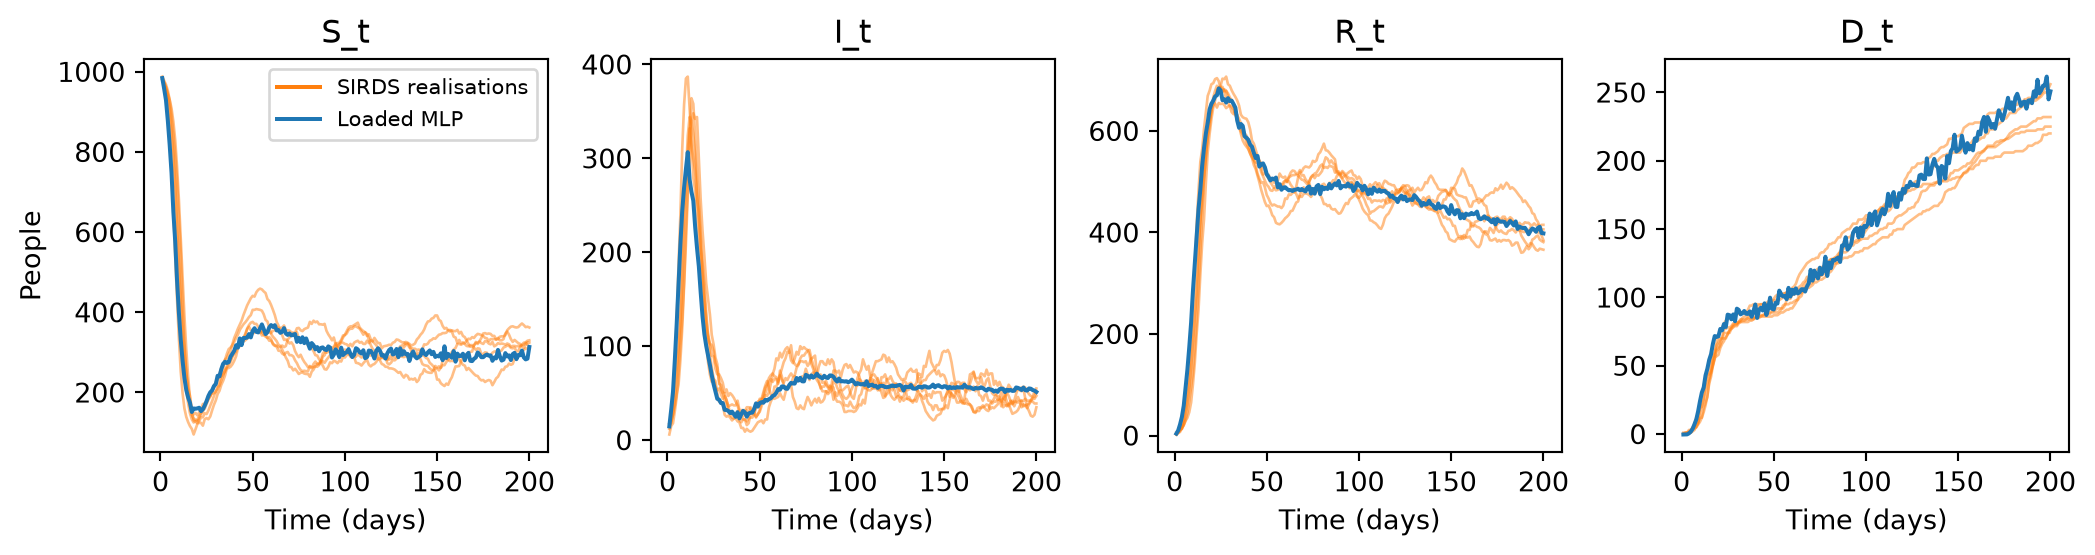

In [4]:
#| fig-cap: "Saved and reloaded MLP fitted on the bundled SIRDS training partition, compared with all five realisations at one test setting."
indices = [i for i, key in enumerate(split.test.group_keys)
           if key == split.test.group_keys[0]]
fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharex=True)
for channel, (ax, name) in enumerate(zip(axes, bank.output_names)):
    ax.plot(bank.times, split.test.outputs[indices, :, channel].T,
            color="C1", alpha=0.5, linewidth=1)
    ax.plot([], [], color="C1", label="SIRDS realisations")
    ax.plot(restored.times, prediction[0, :, channel], color="C0", label="Loaded MLP")
    ax.set(title=name, xlabel="Time (days)")
axes[0].set_ylabel("People")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

*Saved and reloaded MLP fitted on the bundled SIRDS training partition, compared with all five realisations at one test setting.*

To make predictions for several scenarios at once, pass a data frame with the
same input column names:

In [5]:
scenarios = pd.DataFrame(split.test.inputs[::5], columns=bank.input_names)
trajectories = restored.predict(scenarios)
print(f"Predicted {len(trajectories)} SIRDS scenarios")

Predicted 200 SIRDS scenarios


/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0', 'beta', 'gamma', 'mu']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


For a saved stochastic surrogate, use `sample(new_inputs, n_samples=100,
seed=42)` to generate multiple realisations. The result has shape
`(settings, samples, time points, outputs)`. These are the same methods you
would call inside a dashboard or a model fitting script.

## Checkpointing

For a longer training run, save checkpoints periodically so an interruption
does not lose all progress. The checkpoint contains optimizer and random
states as well as weights. In Python, set these fields in `TrainingConfig`:

```python
config = TrainingConfig(
    steps=10000,
    checkpoint_every=500,
    checkpoint_dir="checkpoints/sirds",
)
model = Surrogate("mlp").fit(split.train, split.validation, config=config)
```

To resume an interrupted run, repeat its settings and add `resume_from`:

```python
config = TrainingConfig(
    steps=10000,
    checkpoint_every=500,
    checkpoint_dir="checkpoints/sirds",
    resume_from="checkpoints/sirds/last.pt",
)
model = Surrogate("mlp").fit(split.train, split.validation, config=config)
```

`steps` is the original total, not a number of extra updates. Keep the same
bank, split, model and training settings; METIS checks them before continuing.
After training, call `model.save(...)` to create the file used for predictions.
A training checkpoint cannot be loaded with `Surrogate.load`.

The same options are available through Hydra:

```bash
uv run metis train \
  hydra.run.dir=outputs/sirds-training \
  training.steps=10000 \
  training.checkpoint_every=500 \
  training.checkpoint_dir=checkpoints/sirds
```

Hydra puts the relative checkpoint directory inside the run directory. To
resume from the same working directory, use the full path from there:

```bash
uv run metis train \
  hydra.run.dir=outputs/sirds-training \
  training.steps=10000 \
  training.checkpoint_every=500 \
  training.checkpoint_dir=checkpoints/sirds \
  training.resume_from=outputs/sirds-training/checkpoints/sirds/last.pt
```

See the [Hydra guide](https://ojwatson.github.io/metis/basics/hydra.html) for longer command-line workflows.